# <span style="color:red"><center>Construcción automática de texto </center></span>

<center>Introducción</center>

<figure>
<center>
<img src="../Imagenes/text_generation_sampling.png" width="800" height="600" align="center"/>
</center>
<figcaption>
<p style="text-align:center">Muestreo  de palabras</p>
</figcaption>
</figure>

Fuente: [Text generation with an RNN](https://www.tensorflow.org/tutorials/text/text_generation)

##   <span style="color:blue">Referencias</span>

1. Basado en el blog de laurencemoroney: (https://storage.googleapis.com/laurencemoroney-blog.appspot.com/sonnets.txt)

##   <span style="color:blue">Contenido</span>

* [Introducción](#Introducción)
* [Datos](#Datos)
* [Preprocesamiento](#Preprocesamiento)
* [Librerías](#Librerías)
* [Lee los datos](#Lee-los-datos)
* [Tokeniza el texto](#Lee-los-datos)
* [Crea n-Grams para datos de entrenamiento y etiquetas](#Crea-n-Grams-para-datos-de-entrenamiento-y-etiquetas)
* [Crea-el-modelo](#Crea-el-modelo)
* [Genera-texto-automáticamente](#Genera-texto-automáticamente)

In [1]:
!pip install tensorflow

In [2]:
import tensorflow as tf
print(tf.__version__)

# !pip install -q tensorflow-datasets

2.17.1


In [3]:
#pip install --upgrade tensorflow

In [4]:
#!pip3 install "numpy<2.0.0"

##   <span style="color:blue">Introducción</span>

Gran conjunto de datos basado en sonetos de Shekespeare.


##   <span style="color:blue">Librerías</span>


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import regularizers
from tensorflow.keras.utils import to_categorical
import numpy as np 
from tensorflow.keras.models import load_model

from tensorflow.keras.utils import plot_model

## <span style="color:blue">Lee los datos</span>

In [6]:
#!wget --no-check-certificate \
#    https://storage.googleapis.com/laurencemoroney-blog.appspot.com/sonnets.txt \
#    -O /tmp/sonnets.txt
data = open('../Datos/sonnets.txt').read()

corpus = data.lower().split("\n")

## <span style="color:blue">Tokeniza el texto</span>


In [7]:
tokenizer = Tokenizer()

corpus = data.lower().split("\n")
tokenizer.fit_on_texts(corpus)
total_words = len(tokenizer.word_index) + 1

#print('Dictionary: ',tokenizer.word_index,'\n')
print('índice de sonnets = ',tokenizer.word_index['sonnets'])
print('\nTNúmero total d palabras en el Tokenizador (+OOV) =',total_words,'\n')

# Muestra parte del corpus
print('Primeras líneas del corpus: \n')
corpus[0:10]

índice de sonnets =  878

TNúmero total d palabras en el Tokenizador (+OOV) = 3375 

Primeras líneas del corpus: 



['\tsonnets',
 '',
 '',
 '',
 'to the only begetter of',
 'these insuing sonnets',
 'mr. w. h. all happiness',
 'and that eternity',
 'promised by',
 'our ever-living poet wisheth']

## <span style="color:blue">Crea n-Grams para datos de entrenamiento y etiquetas</span>


In [8]:
# crear secuencias de entrada usando una lista de tokens
input_sequences = []
for line in corpus:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)
        
print('input_sequences[0:10] = ',input_sequences[:10],'\n')

# Determine el n-gram más largo
max_seq_test_len = max([len(x) for x in input_sequences])
print('\nlongitud del  n-grama más largo:',max_seq_test_len)


input_sequences[0:10] =  [[3, 2], [3, 2, 313], [3, 2, 313, 1375], [3, 2, 313, 1375, 4], [118, 1376], [118, 1376, 878], [1377, 1378], [1377, 1378, 1379], [1377, 1378, 1379, 23], [1377, 1378, 1379, 23, 1380]] 


longitud del  n-grama más largo: 11


### ¿Qué hizo tokenizer?

In [9]:
line = corpus[21]
token_list = tokenizer.texts_to_sequences([line])
print(line)
print(token_list)
print(token_list[0])

his tender heir might bear his memory:
[[25, 314, 637, 103, 200, 25, 280]]
[25, 314, 637, 103, 200, 25, 280]


[25, 314, 637, 103, 200, 25, 280]
[0,0,0,0,0,0,0,0,0,25,314] -> x: [0,0,0,0,0,0,0,0,0,25] y: [314] 
[0,0,0,0,0,0,0,0,25,314,637]

### Agrega PAD para tener secuencias de la misma longitud

In [10]:
# pad sequences 
max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

# crea predictores y etiqueta
predictors, label = input_sequences[:,:-1],input_sequences[:,-1]

#

In [11]:
print(input_sequences.shape)
print(predictors.shape)
print(label.shape)

(15484, 11)
(15484, 10)
(15484,)


In [12]:
print(len(predictors))
print(len(label))

15484
15484


In [13]:
print(input_sequences[0:3]) # secuencia completa
print('\n')
print(predictors[0:3]) # secuencia hasta el anterior al último
print('\n')
print(label[0:3]) # el último de la secuencia

[[   0    0    0    0    0    0    0    0    0    3    2]
 [   0    0    0    0    0    0    0    0    3    2  313]
 [   0    0    0    0    0    0    0    3    2  313 1375]]


[[  0   0   0   0   0   0   0   0   0   3]
 [  0   0   0   0   0   0   0   0   3   2]
 [  0   0   0   0   0   0   0   3   2 313]]


[   2  313 1375]


# Convierte etiquetas a 1-hot

If label = [1, 0, 2] and total_words = 4, the output becomes:

[[0, 1, 0, 0],

 [1, 0, 0, 0],
 
 [0, 0, 1, 0]]

In [14]:
label = to_categorical(label, num_classes=total_words)
print(label.shape)

(15484, 3375)


<figure>
<center>
<img src="../Imagenes/bidirectiona_LSTM.png" width="700" height="500" align="center"/>
</center>
<figcaption>
<p style="text-align:center">Bidirectional LSTM</p>
</figcaption>
</figure>


<figure>
<center>
<img src="../Imagenes/dropout-keras.png" width="500" height="400" align="center"/>
</center>
<figcaption>
<p style="text-align:center">Dropout Layer</p>
</figcaption>
</figure>


<figure>
<center>
<img src="../Imagenes/bi_LSTM.png" width="800" height="600" align="center"/>
</center>
<figcaption>
<p style="text-align:center">Modelo RNN Ejemplo</p>
</figcaption>
</figure>


## <span style="color:blue">Crea el modelo</span>

In [15]:
model = Sequential()
model.add(Embedding(total_words, 200, ))
#This line adds a bidirectional LSTM layer to the model with 150 units and return_sequences=True. 
#The bidirectional layer processes the input sequence in both forward and backward directions.
model.add(Bidirectional(LSTM(150, return_sequences = True)))
model.add(Dropout(0.2))
model.add(LSTM(100))
#model.add(Dense(total_words/2, activation='relu', kernel_regularizer=regularizers.l2(0.01)))
model.add(Dense(total_words // 2, activation='relu', kernel_regularizer=regularizers.l2(0.01)))
model.add(Dense(total_words, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.build()

I0000 00:00:1792964452.109455   27425 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792964452.155165   27425 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792964452.157948   27425 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792964452.162350   27425 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

In [16]:
!pip install graphviz

In [17]:
!pip install pydot

In [29]:
print(model.summary())
plot_model(model, to_file='../Imagenes/sonetos.png', 
           show_shapes=True)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 200)        │       675,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 10, 300)        │       421,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │       160,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1687)           │       170,387 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3375)           │     5,697,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,371,963 (81.53 MB)

 Trainable params: 7,123,987 (27.18 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,247,976 (54.35 MB)

None
You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


## <span style="color:blue">Entrena</span>

In [19]:
 history = model.fit(predictors, label, epochs=150, verbose=1)

Epoch 1/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.0206 - loss: 7.3422
Epoch 2/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.0218 - loss: 6.5263
Epoch 3/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.0247 - loss: 6.4229
Epoch 4/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.0310 - loss: 6.2633
Epoch 5/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.0391 - loss: 6.1861
Epoch 6/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.0360 - loss: 6.1446
Epoch 7/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.0374 - loss: 6.1075
Epoch 8/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.0389 - loss: 6.0501
Epoch 9/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.0462 - loss: 5.9405
Epoch 10/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.0466 - loss: 5.8419
Epoch 11/150
484/484 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.0548 - loss: 5.7305
Epoch 12/150
484/484 ━━━━━━━━━━━━━━━

# embedding of the vocabulary

In [25]:
# Get the embedding layer from the model (first layer)
embedding_layer = model.layers[0]

# Get the embedding weights: shape (total_words, embedding_dim=100)
embedding_weights = embedding_layer.get_weights()[0]   # returns a numpy array

# Retrieve the index of the word 'creature' from the tokenizer
word_index = tokenizer.word_index   # dict: word -> integer index
creature_index = word_index.get('love')

if creature_index is not None:
    # Extract the embedding vector (the row corresponding to that index)
    creature_embedding = embedding_weights[creature_index]
    print(f"Embedding vector for 'love' (shape: {creature_embedding.shape}):")
    print(creature_embedding)
else:
    print("The word 'love' is not in the vocabulary.")

Embedding vector for 'love' (shape: (200,)):
[-0.24909869 -0.00398989 -0.05418638  0.02405783  0.04113266 -0.00775643
  0.16359068  0.1716602   0.17119038  0.00347365 -0.03376329  0.44653934
  0.39741835 -0.01275518 -0.01763148 -0.01055238 -0.14305253  0.0738584
  0.1163509   0.25951016  0.53647524  0.09711474  0.13105981  0.00675132
 -0.01126601  0.1809341  -0.00080259  0.15555282  0.14549628  0.22151476
 -0.03971295  0.23664726  0.08239305 -0.08837043 -0.1870826   0.12821776
 -0.05789379 -0.19063216 -0.09122643  0.1356063  -0.03953343  0.1775994
  0.15097544  0.06412708 -0.28767818  0.21369211 -0.20082916 -0.3528402
 -0.07512036 -0.10923191 -0.10326311  0.11401074  0.03655927 -0.092931
  0.13160068  0.1611866  -0.01143362  0.07216095  0.11666954  0.27943835
 -0.19475779  0.06790694  0.34648484 -0.06664898  0.02006852 -0.06592672
  0.23317154  0.13476656 -0.0276721   0.11734363 -0.02986227 -0.18332253
 -0.02082204  0.00665738  0.22254156 -0.37119812 -0.21868631  0.01649352
  0.0105474

In [26]:
model.save("../Saved_Models/rnn_3.keras")

In [27]:
model = load_model("../Saved_Models/rnn_3.keras")

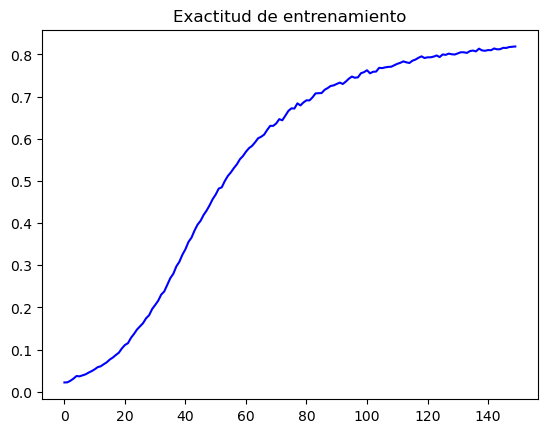

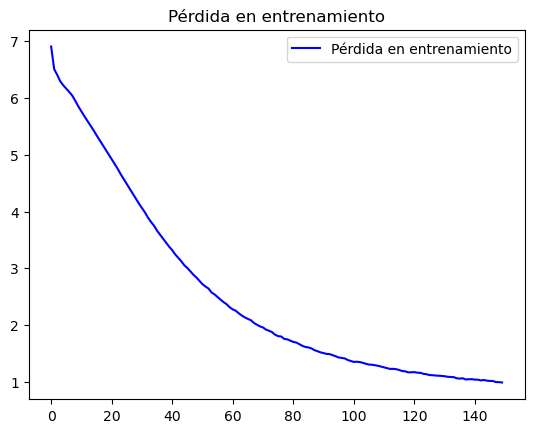

In [28]:
import matplotlib.pyplot as plt
acc = history.history['accuracy']
loss = history.history['loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'b', label='Exactitud de entrenamiento')

plt.title('Exactitud de entrenamiento')

plt.figure()

plt.plot(epochs, loss, 'b', label='Pérdida en entrenamiento')
plt.title('Pérdida en entrenamiento')
plt.legend()

plt.show()

## <span style="color:blue">Genera texto automáticamente</span>

In [24]:
seed_text = "I want to say that I love you but"
next_words = 100
  
for _ in range(next_words):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
    #predicted = model.predict_classes(token_list, verbose=0)
    #predicted = (model.predict(token_list) > 0.5).astype("int32")
    predicted = np.argmax(model.predict(token_list), axis=-1) 
    output_word = ""
    for word, index in tokenizer.word_index.items():
        if index == predicted:
            output_word = word
            break
    seed_text += " " + output_word
print(seed_text)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━